# KIỂM THỬ MÔ HÌNH SMOLVLM2-2.2B-INSTRUCT TRÊN DATASET POPE

## 1. Mục tiêu

Thực hiện đánh giá khả năng nhận diện sự tồn tại của đối tượng trong hình ảnh của mô hình SmolVLM2-2.2B-Instruct thông qua bộ dữ liệu POPE.

Quá trình kiểm thử tập trung vào khả năng trả lời câu hỏi Yes/No dựa trên nội dung hình ảnh, từ đó đánh giá mức độ chính xác và xu hướng tạo ra thông tin sai lệch của mô hình.

## 2. Phương pháp đánh giá

- Sử dụng mô hình SmolVLM2-2.2B-Instruct.
- Sử dụng bộ dữ liệu POPE, tập test gồm 9.000 mẫu.
- Đưa hình ảnh và câu hỏi vào mô hình để tạo câu trả lời.
- So sánh câu trả lời với nhãn thực tế.
- Đánh giá bằng Accuracy, Precision, Recall và F1-score.
- Phân tích False Positive để xác định xu hướng nhận diện nhầm đối tượng không tồn tại.

## Bước 2. Kiểm tra thông tin môi trường thực thi

Kiểm tra phiên bản Python, hệ điều hành, PyTorch và thông tin GPU được Kaggle cung cấp. Qua đó xác nhận môi trường đã đáp ứng yêu cầu để tải và chạy mô hình SmolVLM2-2.2B-Instruct.

In [1]:

import sys
import torch
import platform

print("========== THÔNG TIN MÔI TRƯỜNG ==========")

print("Python:", sys.version)
print("Hệ điều hành:", platform.platform())
print("PyTorch:", torch.__version__)

# Kiểm tra GPU
if torch.cuda.is_available():
    print("\nGPU khả dụng: Có")
    print("Tên GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

    total_memory = torch.cuda.get_device_properties(0).total_memory
    print("Dung lượng GPU:",
          round(total_memory / (1024 ** 3), 2), "GB")
else:
    print("\nGPU khả dụng: Không")
    print("Vui lòng bật GPU trong Kaggle Settings.")

========== THÔNG TIN MÔI TRƯỜNG ==========
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Hệ điều hành: Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130

GPU khả dụng: Có
Tên GPU: Tesla T4
CUDA version: 13.0
Dung lượng GPU: 14.56 GB


## Bước 3. Kiểm tra thư viện và thiết bị thực thi

Kiểm tra thư viện `num2words` và khả năng nhận diện thư viện từ Transformers. Đồng thời, xác định thiết bị thực thi là CPU hay GPU để bảo đảm môi trường đã sẵn sàng cho quá trình tải và chạy mô hình SmolVLM2-2.2B-Instruct.

In [2]:
# Cai thu vien (chay 1 lan, sau do Restart Session roi chay tiep)
%pip install -q --upgrade "transformers>=4.49" accelerate num2words safetensors pillow scikit-learn
print("Da cai xong. Hay Restart Session truoc khi chay tiep.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.
Da cai xong. Hay Restart Session truoc khi chay tiep.


In [3]:
import gc
import torch
import num2words

# Kiểm tra num2words trước
print("num2words:", num2words.num2words(22))

# Import Transformers sau khi num2words đã sẵn sàng
from transformers import AutoProcessor, AutoModelForImageTextToText

from transformers.utils import import_utils

print("Transformers nhận diện num2words:",
      import_utils.is_num2words_available())

# Kiểm tra thiết bị
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Thiết bị:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

num2words: twenty-two
Transformers nhận diện num2words: True
Thiết bị: cuda
GPU: Tesla T4


In [4]:
# (Da gop vao cell cai dat phia tren - khong can chay)

In [5]:
# (Da gop vao cell cai dat phia tren - khong can chay)

In [6]:
# (Da gop vao cell cai dat phia tren - khong can chay)

In [7]:
import torch
import transformers
import tokenizers
import huggingface_hub
import datasets

print("===== KIỂM TRA MÔI TRƯỜNG =====")
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("HuggingFace Hub:", huggingface_hub.__version__)
print("Datasets:", datasets.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

===== KIỂM TRA MÔI TRƯỜNG =====
PyTorch: 2.11.0+cu130
Transformers: 5.24.0
Tokenizers: 0.23.3
HuggingFace Hub: 1.33.0
Datasets: 4.8.5
CUDA: True
GPU: Tesla T4


In [8]:
import sys
import importlib.util
import importlib.metadata

print("1. Python:", sys.executable)

# Kiểm tra thư viện num2words
spec = importlib.util.find_spec("num2words")
print("\n2. Đường dẫn num2words:", spec.origin if spec else "Không tìm thấy")

try:
    import num2words
    print("3. Import num2words: THÀNH CÔNG")
    print("Đường dẫn:", num2words.__file__)
    print("Kiểm tra:", num2words.num2words(22))
except Exception as e:
    print("3. Import num2words: THẤT BẠI")
    print(type(e).__name__, e)

# Kiểm tra phiên bản
try:
    print("\n4. Phiên bản num2words:",
          importlib.metadata.version("num2words"))
except Exception as e:
    print("Không lấy được phiên bản:", e)

# Kiểm tra Transformers có nhận diện num2words không
try:
    from transformers.utils import import_utils
    print("\n5. Transformers nhận diện num2words:",
          import_utils.is_num2words_available())
except Exception as e:
    print("Lỗi kiểm tra Transformers:", e)

1. Python: /usr/bin/python3

2. Đường dẫn num2words: /usr/local/lib/python3.13/dist-packages/num2words/__init__.py
3. Import num2words: THÀNH CÔNG
Đường dẫn: /usr/local/lib/python3.13/dist-packages/num2words/__init__.py
Kiểm tra: twenty-two

4. Phiên bản num2words: 0.5.14

5. Transformers nhận diện num2words: True


## Bước 4. Kiểm tra phiên bản thư viện

Kiểm tra phiên bản của các thư viện chính được sử dụng trong quá trình thực nghiệm, bao gồm PyTorch, Transformers, Tokenizers, HuggingFace Hub và Datasets. Đồng thời, xác nhận khả năng sử dụng CUDA và thông tin GPU nhằm hạn chế các lỗi không tương thích trong quá trình chạy mô hình.

In [9]:
import importlib
import num2words

# Làm mới module kiểm tra thư viện của Transformers
from transformers.utils import import_utils

importlib.reload(import_utils)

print("Kiểm tra num2words:",
      import_utils.is_num2words_available())

# Kiểm tra lại module
print("Đường dẫn:", num2words.__file__)
print("Thử chuyển số:", num2words.num2words(22))

Kiểm tra num2words: True
Đường dẫn: /usr/local/lib/python3.13/dist-packages/num2words/__init__.py
Thử chuyển số: twenty-two


In [10]:
import gc
import torch
import num2words

from transformers import AutoProcessor, AutoModelForImageTextToText

MODEL_NAME = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Thiết bị:", device)

# Giải phóng bộ nhớ
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Chọn kiểu dữ liệu
dtype = torch.float16 if device == "cuda" else torch.float32

try:
    print("\nĐang tải Processor...")
    processor = AutoProcessor.from_pretrained(MODEL_NAME)

    print("Processor đã tải thành công!")

    print("\nĐang tải mô hình SmolVLM2...")
    model = AutoModelForImageTextToText.from_pretrained(
        MODEL_NAME,
        torch_dtype=dtype,
        device_map="auto" if device == "cuda" else None,
        low_cpu_mem_usage=True
    )

    model.eval()

    print("\nTẢI MÔ HÌNH THÀNH CÔNG!")
    print("Tên mô hình:", MODEL_NAME)
    print("GPU:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")
    print("Kiểu dữ liệu:", dtype)

except Exception as e:
    print("\nLỖI:", type(e).__name__, str(e))
    raise

Thiết bị: cuda

Đang tải Processor...


processor_config.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/517 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.7k [00:00<?, ?B/s]

... (7 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]


TẢI MÔ HÌNH THÀNH CÔNG!
Tên mô hình: HuggingFaceTB/SmolVLM2-2.2B-Instruct
GPU: Tesla T4
Kiểu dữ liệu: torch.float16


TẢI VÀ KHẢO SÁT DATASET POPE

Trong bước này, tiến hành tải bộ dữ liệu POPE từ Hugging Face. Đây là bộ dữ liệu được sử dụng để đánh giá hiện tượng Hallucination thông qua các câu hỏi xác định sự tồn tại của đối tượng trong hình ảnh.



In [11]:


from datasets import load_dataset

DATASET_NAME = "lmms-lab-encoder/POPE"

print("Đang tải dataset POPE...")

dataset = load_dataset(DATASET_NAME)

print("\nTải dataset thành công!")
print(dataset)

Đang tải dataset POPE...


README.md:   0%|          | 0.00/2.16k [00:00<?, ?B/s]

data/test-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/9000 [00:00<?, ? examples/s]


Tải dataset thành công!
DatasetDict({
    test: Dataset({
        features: ['id', 'question_id', 'question', 'answer', 'image_source', 'image', 'category'],
        num_rows: 9000
    })
})


In [12]:


print("Các tập dữ liệu:", list(dataset.keys()))

for split in dataset.keys():
    print(f"\nTập: {split}")
    print("Số lượng mẫu:", len(dataset[split]))
    print("Các cột:", dataset[split].column_names)

# Hiển thị một mẫu dữ liệu
sample = dataset[list(dataset.keys())[0]][0]

print("\nMẪU DỮ LIỆU:")
for key, value in sample.items():
    if key == "image":
        print(key, ":", value)
    else:
        print(key, ":", value)

Các tập dữ liệu: ['test']

Tập: test
Số lượng mẫu: 9000
Các cột: ['id', 'question_id', 'question', 'answer', 'image_source', 'image', 'category']

MẪU DỮ LIỆU:
id : 0
question_id : 1
question : Is there a snowboard in the image?
answer : yes
image_source : COCO_val2014_000000310196
image : <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=640x427 at 0x7DE87617D160>
category : adversarial


 PHÂN TÍCH VÀ KIỂM TRA DATASET POPE

Tiến hành khảo sát dữ liệu nhằm xác định phân bố nhãn Yes/No và các nhóm câu hỏi trong POPE. Đồng thời, kiểm tra định dạng hình ảnh để đảm bảo dữ liệu phù hợp với đầu vào của mô hình SmolVLM2.



In [13]:

from collections import Counter
import pandas as pd

test_data = dataset["test"]

# Thống kê nhãn thực tế
answer_counts = Counter(
    str(item).strip().lower() for item in test_data["answer"]
)

# Thống kê nhóm câu hỏi
category_counts = Counter(test_data["category"])

print("========== PHÂN BỐ NHÃN ==========")

for label, count in answer_counts.items():
    print(f"{label}: {count} mẫu ({count / len(test_data) * 100:.2f}%)")

print("\n========== PHÂN BỐ CATEGORY ==========")

for category, count in category_counts.items():
    print(f"{category}: {count} mẫu ({count / len(test_data) * 100:.2f}%)")

# Tạo bảng thống kê
summary = pd.DataFrame({
    "Nhãn": list(answer_counts.keys()),
    "Số lượng": list(answer_counts.values())
})

display(summary)

========== PHÂN BỐ NHÃN ==========
yes: 4500 mẫu (50.00%)
no: 4500 mẫu (50.00%)

========== PHÂN BỐ CATEGORY ==========
adversarial: 3000 mẫu (33.33%)
popular: 3000 mẫu (33.33%)
random: 3000 mẫu (33.33%)


,Nhãn,Số lượng
0,yes,4500
1,no,4500


========== KIỂM TRA DỮ LIỆU THIẾU ==========
id: 0 giá trị thiếu
question_id: 0 giá trị thiếu
question: 0 giá trị thiếu
answer: 0 giá trị thiếu
image_source: 0 giá trị thiếu
image: 0 giá trị thiếu
category: 0 giá trị thiếu

========== THÔNG TIN HÌNH ẢNH ==========
Định dạng: JPEG
Chế độ màu: RGB
Kích thước: (640, 427)


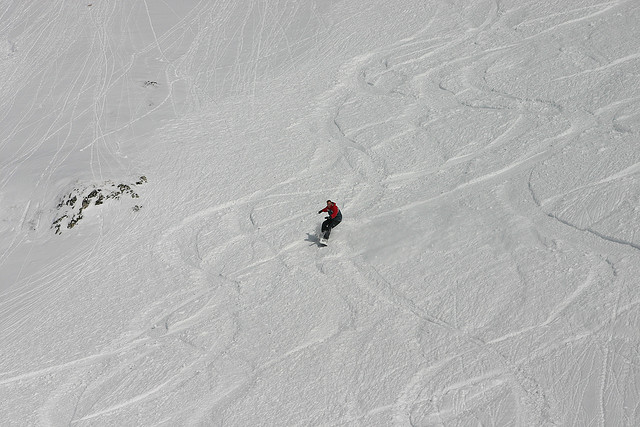

In [14]:


missing_counts = {
    column: sum(value is None for value in test_data[column])
    for column in test_data.column_names
}

print("========== KIỂM TRA DỮ LIỆU THIẾU ==========")

for column, count in missing_counts.items():
    print(f"{column}: {count} giá trị thiếu")

# Kiểm tra hình ảnh
image = test_data[0]["image"]

print("\n========== THÔNG TIN HÌNH ẢNH ==========")
print("Định dạng:", image.format)
print("Chế độ màu:", image.mode)
print("Kích thước:", image.size)

# Hiển thị hình ảnh mẫu
display(image)

CHUẨN BỊ DỮ LIỆU ĐẦU VÀO

Ở bước này, tiến hành chuẩn hóa dữ liệu POPE trước khi đưa vào mô hình SmolVLM2.



In [15]:

from PIL import Image

test_data = dataset["test"]

benchmark_data = []

for idx, sample in enumerate(test_data):

    # Chuẩn hóa hình ảnh
    image = sample["image"].convert("RGB")

    # Chuẩn hóa câu hỏi
    question = str(sample["question"]).strip()

    # Chuẩn hóa nhãn thực tế
    answer = str(sample["answer"]).strip().lower()

    # Chỉ giữ các nhãn hợp lệ
    if answer not in ["yes", "no"]:
        continue

    benchmark_data.append({
        "id": f'{sample["category"]}_{sample["id"]}',
        "question": question,
        "image": image,
        "answer": answer,
        "category": sample["category"],
        "image_source": sample["image_source"]
    })

print("========== KẾT QUẢ TIỀN XỬ LÝ ==========")
print("Tổng số mẫu ban đầu:", len(test_data))
print("Số mẫu hợp lệ:", len(benchmark_data))
print("Số mẫu bị loại:", len(test_data) - len(benchmark_data))

========== KẾT QUẢ TIỀN XỬ LÝ ==========
Tổng số mẫu ban đầu: 9000
Số mẫu hợp lệ: 9000
Số mẫu bị loại: 0


ID: adversarial_0
So id duy nhat: 9000 / 9000
Question: Is there a snowboard in the image?
Ground Truth: yes
Category: adversarial
Image Source: COCO_val2014_000000310196
Image Size: (640, 427)


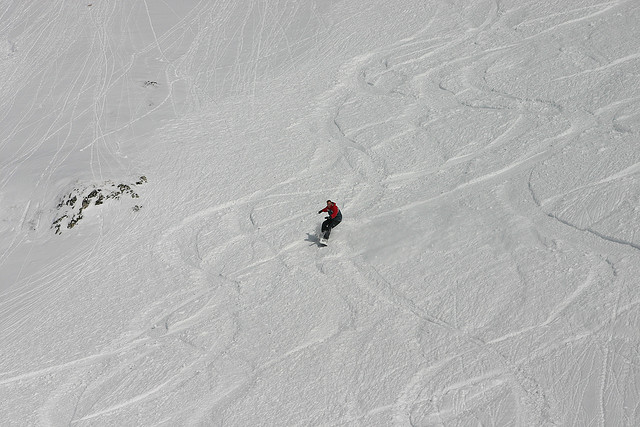

In [16]:


sample = benchmark_data[0]

print("ID:", sample["id"])
print("So id duy nhat:", len({d["id"] for d in benchmark_data}), "/", len(benchmark_data))
print("Question:", sample["question"])
print("Ground Truth:", sample["answer"])
print("Category:", sample["category"])
print("Image Source:", sample["image_source"])
print("Image Size:", sample["image"].size)

display(sample["image"])

 THIẾT LẬP QUY TRÌNH SUY LUẬN

Trong bước này, xây dựng hàm Inference để đưa hình ảnh và câu hỏi từ POPE vào mô hình SmolVLM2-2.2B-Instruct.

Mô hình được yêu cầu xác định đối tượng có xuất hiện trong hình ảnh hay không và chỉ trả lời bằng một trong hai nhãn Yes hoặc No.

Quy trình thực hiện:
1. Nhận hình ảnh và câu hỏi.
2. Chuyển dữ liệu thành định dạng đầu vào của SmolVLM2.
3. Thực hiện sinh câu trả lời.
4. Giải mã kết quả đầu ra.
5. Chuẩn hóa câu trả lời thành Yes hoặc No.

In [17]:
# (Ham predict_smollvm ban dung nam o cell BUOC 8 phia duoi)

In [18]:
# BƯỚC 7: KIỂM TRA KÍCH THƯỚC ĐẦU VÀO CỦA SMOLVLM2

import torch
import transformers

sample = benchmark_data[0]
image = sample["image"].convert("RGB")
question = sample["question"]

print("Transformers version:", transformers.__version__)
print("Image size:", image.size)
print("Image mode:", image.mode)

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image"},
            {
                "type": "text",
                "text": f"{question}\nAnswer only Yes or No."
            }
        ]
    }
]

prompt = processor.apply_chat_template(
    messages,
    add_generation_prompt=True
)

inputs = processor(
    text=prompt,
    images=image,
    return_tensors="pt"
)

print("\n========== INPUT SHAPES ==========")

for key, value in inputs.items():
    if isinstance(value, torch.Tensor):
        print(key, value.shape, value.dtype)

print("\n========== MODEL CONFIG ==========")
print("Patch size:", model.config.vision_config.patch_size)
print("Hidden size:", model.config.vision_config.hidden_size)

Transformers version: 5.24.0
Image size: (640, 427)
Image mode: RGB

========== INPUT SHAPES ==========
input_ids torch.Size([1, 1107]) torch.int64
attention_mask torch.Size([1, 1107]) torch.int64
pixel_values torch.Size([1, 13, 3, 384, 384]) torch.float32
pixel_attention_mask torch.Size([1, 13, 384, 384]) torch.int64

========== MODEL CONFIG ==========
Patch size: 14
Hidden size: 1152


In [19]:

# BƯỚC 8: HÀM DỰ ĐOÁN SMOLVLM2 ĐÃ ĐIỀU CHỈNH

import torch
import time

def predict_smollvm(image, question):
    image = image.convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image
                },
                {
                    "type": "text",
                    "text": (
                        f"{question}\n"
                        "Answer only Yes or No. "
                        "Base your answer strictly on the image."
                    )
                }
            ]
        }
    ]

    # Xử lý ảnh và văn bản trực tiếp qua chat template
    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(model.device)

    # Sinh câu trả lời
    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=10,
            do_sample=False
        )

    # Chỉ giải mã phần token mới được sinh
    input_length = inputs["input_ids"].shape[1]

    response = processor.decode(
        outputs[0][input_length:],
        skip_special_tokens=True
    ).strip()

    return response


 CHUẨN HÓA CÂU TRẢ LỜI

Câu trả lời của SmolVLM2 có thể xuất hiện dưới nhiều dạng như Yes, Yes., No hoặc No.

Trong bước này, xây dựng hàm chuẩn hóa kết quả thành hai nhãn thống nhất:
- yes: Đối tượng xuất hiện trong hình ảnh.
- no: Đối tượng không xuất hiện trong hình ảnh.
- unknown: Câu trả lời không xác định được hai nhãn trên.

Việc chuẩn hóa giúp đảm bảo tính nhất quán khi đối chiếu dự đoán với nhãn thực tế.

In [20]:

import re

def normalize_answer(response):
    text = response.strip().lower()

    # Tìm câu trả lời Yes hoặc No ở đầu phản hồi
    match = re.match(r"^(yes|no)\b", text)

    if match:
        return match.group(1)

    return "unknown"


# Kiểm tra hàm chuẩn hóa
test_responses = [
    "Yes",
    "Yes.",
    "No",
    "No.",
    "The answer is yes.",
    "I cannot determine."
]

for response in test_responses:
    print(f"{response:25} -> {normalize_answer(response)}")

Yes                       -> yes
Yes.                      -> yes
No                        -> no
No.                       -> no
The answer is yes.        -> unknown
I cannot determine.       -> unknown


In [21]:
sample = benchmark_data[0]
prediction = predict_smollvm(sample["image"], sample["question"])
normalized_prediction = normalize_answer(prediction)

print("Ground Truth:", sample["answer"])
print("Raw Prediction:", prediction)
print("Normalized Prediction:", normalized_prediction)

if normalized_prediction == sample["answer"]:
    print("Ket qua: DUNG")
elif normalized_prediction == "unknown":
    print("Ket qua: KHONG XAC DINH")
else:
    print("Ket qua: SAI")

Ground Truth: yes
Raw Prediction: No.
Normalized Prediction: no
Ket qua: SAI


THỰC HIỆN BENCHMARK TRÊN DATASET POPE

Tiến hành đưa toàn bộ 9.000 mẫu trong tập test POPE vào mô hình SmolVLM2-2.2B-Instruct để đánh giá khả năng nhận diện đối tượng trong hình ảnh.

Với mỗi mẫu, mô hình sẽ:
- Nhận hình ảnh và câu hỏi tương ứng.
- Sinh câu trả lời Yes/No.
- Chuẩn hóa câu trả lời.
- Đối chiếu với nhãn thực tế.
- Ghi nhận thời gian suy luận.

Kết quả được lưu lại để sử dụng trong quá trình tính toán các chỉ số đánh giá.

In [22]:


import time
import pandas as pd
from tqdm.auto import tqdm

# Danh sách lưu kết quả
benchmark_results = []

# Thống kê thời gian
total_start_time = time.time()

print("========== BENCHMARK CONFIGURATION ==========")
print("Model:", MODEL_NAME)
print("Dataset: POPE")
print("Split: test")
print("Total samples:", len(benchmark_data))
print("Device:", device)
print("Batch size: 1")
print("Generation max tokens: 10")
print("Sampling: Disabled")

========== BENCHMARK CONFIGURATION ==========
Model: HuggingFaceTB/SmolVLM2-2.2B-Instruct
Dataset: POPE
Split: test
Total samples: 9000
Device: cuda
Batch size: 1
Generation max tokens: 10
Sampling: Disabled


In [23]:
# KHÔI PHỤC DANH SÁCH DỮ LIỆU BENCHMARK

from PIL import Image

# Kiểm tra dataset
if "dataset" not in globals():
    from datasets import load_dataset

    dataset = load_dataset("lmms-lab-encoder/POPE")

test_data = dataset["test"]

benchmark_data = []

for sample in test_data:
    answer = str(sample["answer"]).strip().lower()

    if answer not in ["yes", "no"]:
        continue

    benchmark_data.append({
        "id": f'{sample["category"]}_{sample["id"]}',
        "question": str(sample["question"]).strip(),
        "image": sample["image"].convert("RGB"),
        "answer": answer,
        "category": sample["category"],
        "image_source": sample["image_source"]
    })

print("Khôi phục dữ liệu thành công!")
print("Tổng số mẫu:", len(benchmark_data))
print("Mẫu đầu tiên:", benchmark_data[0]["question"])

Khôi phục dữ liệu thành công!
Tổng số mẫu: 9000
Mẫu đầu tiên: Is there a snowboard in the image?


In [24]:
# BƯỚC 5: KIỂM TRA MODEL VÀ DATASET

import torch

print("Model:", "Đã nạp" if "model" in globals() else "Chưa nạp")
print("Processor:", "Đã nạp" if "processor" in globals() else "Chưa nạp")
print("Dataset:", len(dataset["test"]))
print("Benchmark data:", len(benchmark_data))
print("CUDA:", torch.cuda.is_available())

if "model" in globals():
    print("Model device:", model.device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Model: Đã nạp
Processor: Đã nạp
Dataset: 9000
Benchmark data: 9000
CUDA: True
Model device: cuda:0
GPU: Tesla T4


In [25]:
# Nap model neu chua co (tranh tai 2 lan)
import gc, torch
MODEL_NAME = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"
if "model" in globals() and "processor" in globals():
    print("Model da duoc nap o cell truoc, bo qua.")
else:
    from transformers import AutoProcessor, AutoModelForImageTextToText
    gc.collect(); torch.cuda.empty_cache()
    processor = AutoProcessor.from_pretrained(MODEL_NAME)
    model = AutoModelForImageTextToText.from_pretrained(
        MODEL_NAME, torch_dtype=torch.float16, _attn_implementation="eager"
    ).to("cuda")
    model.eval()
print("Model:", MODEL_NAME, "| Device:", model.device)

Model da duoc nap o cell truoc, bo qua.
Model: HuggingFaceTB/SmolVLM2-2.2B-Instruct | Device: cuda:0


In [26]:
# BƯỚC 11.1: KIỂM TRA VÀ KHỞI TẠO CHECKPOINT

import os
import pandas as pd

CHECKPOINT_PATH = "/kaggle/working/pope_smollvm2_checkpoint.csv"
JSON_PATH = "/kaggle/working/pope_smollvm2_checkpoint.json"

benchmark_results = []
completed_ids = set()

if os.path.exists(CHECKPOINT_PATH) and os.path.getsize(CHECKPOINT_PATH) > 0:
    try:
        old_df = pd.read_csv(CHECKPOINT_PATH)

        if "id" in old_df.columns:
            done = old_df[old_df["status"].astype(str).isin(["success","unknown_response"])]
            benchmark_results = done.to_dict("records")
            completed_ids = set(done["id"].astype(str).tolist())

        print("Đã khôi phục:", len(benchmark_results), "kết quả")

    except pd.errors.EmptyDataError:
        print("Checkpoint rỗng, sẽ bắt đầu benchmark mới.")

else:
    print("Chưa có checkpoint hợp lệ, sẽ bắt đầu benchmark mới.")

print("Số kết quả hiện tại:", len(benchmark_results))
print("Số mẫu đã hoàn thành:", len(completed_ids))
print("Số mẫu còn lại:", len(benchmark_data) - len(completed_ids))

Chưa có checkpoint hợp lệ, sẽ bắt đầu benchmark mới.
Số kết quả hiện tại: 0
Số mẫu đã hoàn thành: 0
Số mẫu còn lại: 9000


In [27]:
# BƯỚC 11.3: CHẠY BENCHMARK POPE

import os
import json
import time
import pandas as pd
import torch
from tqdm.auto import tqdm

CHECKPOINT_PATH = "/kaggle/working/pope_smollvm2_checkpoint.csv"
JSON_PATH = "/kaggle/working/pope_smollvm2_checkpoint.json"

SAVE_INTERVAL = 10

# Khởi tạo kết quả
benchmark_results = []
completed_ids = set()
# Khoi phuc tu checkpoint (khong ghi de)
if os.path.exists(CHECKPOINT_PATH) and os.path.getsize(CHECKPOINT_PATH) > 0:
    _old = pd.read_csv(CHECKPOINT_PATH)
    _done = _old[_old["status"].astype(str).isin(["success", "unknown_response"])]
    benchmark_results = _done.to_dict("records")
    completed_ids = set(_done["id"].astype(str))
    print("Da khoi phuc", len(completed_ids), "mau tu checkpoint")

# Lưu checkpoint an toàn
def save_checkpoint():
    if not benchmark_results:
        return

    df = pd.DataFrame(benchmark_results)

    temp_csv = CHECKPOINT_PATH + ".tmp"
    temp_json = JSON_PATH + ".tmp"

    df.to_csv(temp_csv, index=False, encoding="utf-8-sig")
    os.replace(temp_csv, CHECKPOINT_PATH)

    with open(temp_json, "w", encoding="utf-8") as f:
        json.dump(benchmark_results, f, ensure_ascii=False, indent=2)

    os.replace(temp_json, JSON_PATH)

# Chạy benchmark
model.eval()

start_time = time.time()
new_count = 0
error_count = 0

try:
    for item in tqdm(benchmark_data, desc="POPE Benchmark"):

        sample_id = str(item["id"])

        if sample_id in completed_ids:
            continue

        inference_start = time.time()

        try:
            raw_response = predict_smollvm(
                item["image"],
                item["question"]
            )

            prediction = normalize_answer(raw_response)
            status = "success"

            if prediction == "unknown":
                status = "unknown_response"

        except Exception as e:
            raw_response = ""
            prediction = "unknown"
            status = f"error: {str(e)[:250]}"
            error_count += 1

        inference_time = time.time() - inference_start

        benchmark_results.append({
            "id": item["id"],
            "question": item["question"],
            "ground_truth": item["answer"],
            "raw_response": raw_response,
            "prediction": prediction,
            "category": item["category"],
            "inference_time": round(inference_time, 4),
            "status": status
        })

        if not status.startswith("error"):
            completed_ids.add(sample_id)
        new_count += 1

        # Lưu mỗi 10 mẫu
        if new_count % SAVE_INTERVAL == 0:
            save_checkpoint()

        # Hiển thị tiến độ mỗi 50 mẫu
        if new_count % 50 == 0:
            print(
                f"Đã xử lý: {len(benchmark_results)}/9000 | "
                f"Lỗi: {error_count}"
            )

except KeyboardInterrupt:
    print("\nBenchmark đã được dừng thủ công.")

finally:
    save_checkpoint()

    elapsed = time.time() - start_time

    print("\n========== BENCHMARK STATUS ==========")
    print("Đã xử lý:", len(benchmark_results), "/ 9000")
    print("Lỗi:", error_count)
    print("Thời gian:", round(elapsed / 60, 2), "phút")
    print("Checkpoint:", CHECKPOINT_PATH)
    print("Đã lưu kết quả.")

POPE Benchmark:   0%|          | 0/9000 [00:00<?, ?it/s]

Đã xử lý: 50/9000 | Lỗi: 0
Đã xử lý: 100/9000 | Lỗi: 0
Đã xử lý: 150/9000 | Lỗi: 0
Đã xử lý: 200/9000 | Lỗi: 0
Đã xử lý: 250/9000 | Lỗi: 0
Đã xử lý: 300/9000 | Lỗi: 0
Đã xử lý: 350/9000 | Lỗi: 0
Đã xử lý: 400/9000 | Lỗi: 0
Đã xử lý: 450/9000 | Lỗi: 0
Đã xử lý: 500/9000 | Lỗi: 0
Đã xử lý: 550/9000 | Lỗi: 0
Đã xử lý: 600/9000 | Lỗi: 0
Đã xử lý: 650/9000 | Lỗi: 0
Đã xử lý: 700/9000 | Lỗi: 0
Đã xử lý: 750/9000 | Lỗi: 0
Đã xử lý: 800/9000 | Lỗi: 0
Đã xử lý: 850/9000 | Lỗi: 0
Đã xử lý: 900/9000 | Lỗi: 0
Đã xử lý: 950/9000 | Lỗi: 0
Đã xử lý: 1000/9000 | Lỗi: 0
Đã xử lý: 1050/9000 | Lỗi: 0
Đã xử lý: 1100/9000 | Lỗi: 0
Đã xử lý: 1150/9000 | Lỗi: 0
Đã xử lý: 1200/9000 | Lỗi: 0
Đã xử lý: 1250/9000 | Lỗi: 0
Đã xử lý: 1300/9000 | Lỗi: 0
Đã xử lý: 1350/9000 | Lỗi: 0
Đã xử lý: 1400/9000 | Lỗi: 0
Đã xử lý: 1450/9000 | Lỗi: 0
Đã xử lý: 1500/9000 | Lỗi: 0
Đã xử lý: 1550/9000 | Lỗi: 0
Đã xử lý: 1600/9000 | Lỗi: 0
Đã xử lý: 1650/9000 | Lỗi: 0
Đã xử lý: 1700/9000 | Lỗi: 0
Đã xử lý: 1750/9000 | Lỗi: 0
Đã xử

In [28]:
import os
import pandas as pd

CHECKPOINT_PATH = "/kaggle/working/pope_smollvm2_checkpoint.csv"

# Đọc kết quả Benchmark
if os.path.exists(CHECKPOINT_PATH) and os.path.getsize(CHECKPOINT_PATH) > 0:
    results_df = pd.read_csv(CHECKPOINT_PATH)
else:
    results_df = pd.DataFrame(benchmark_results)

print("========== TỔNG HỢP KẾT QUẢ POPE ==========")
print("Tổng số mẫu:", len(results_df))

if "status" in results_df.columns:
    success_df = results_df[
        results_df["status"].astype(str).str.lower() == "success"
    ].copy()
else:
    success_df = results_df.copy()

print("Số mẫu thành công:", len(success_df))

# Thống kê câu trả lời
if "prediction" in results_df.columns:
    print("\nPhân bố dự đoán:")
    print(results_df["prediction"].value_counts(dropna=False))

if "status" in results_df.columns:
    print("\nPhân bố trạng thái:")
    print(results_df["status"].value_counts(dropna=False))

print("\n5 kết quả đầu tiên:")
display(results_df.head())

========== TỔNG HỢP KẾT QUẢ POPE ==========
Tổng số mẫu: 8607
Số mẫu thành công: 8607

Phân bố dự đoán:
prediction
no     4723
yes    3884
Name: count, dtype: int64

Phân bố trạng thái:
status
success    8607
Name: count, dtype: int64

5 kết quả đầu tiên:


,id,question,ground_truth,raw_response,prediction,category,inference_time,status
0,adversarial_0,Is there a snowboard in the image?,yes,No.,no,adversarial,1.1026,success
1,adversarial_1,Is there a backpack in the image?,no,No.,no,adversarial,0.9546,success
2,adversarial_2,Is there a person in the image?,yes,Yes.,yes,adversarial,0.9248,success
3,adversarial_3,Is there a car in the image?,no,No.,no,adversarial,0.9326,success
4,adversarial_4,Is there a skis in the image?,yes,No.,no,adversarial,0.9544,success


In [35]:
# Kiểm tra cấu trúc dữ liệu
print("========== KIỂM TRA DỮ LIỆU ==========")

print("\nCác cột hiện có:")
print(results_df.columns.tolist())

print("\nSố dòng dữ liệu:", len(results_df))

# Kiểm tra trạng thái
if "status" in results_df.columns:
    print("\nPhân bố status:")
    print(results_df["status"].value_counts(dropna=False))

# Kiểm tra nhãn thực tế
if "ground_truth" in results_df.columns:
    print("\nPhân bố ground_truth:")
    print(results_df["ground_truth"].value_counts(dropna=False))

# Kiểm tra dự đoán
if "prediction" in results_df.columns:
    print("\nPhân bố prediction:")
    print(results_df["prediction"].value_counts(dropna=False))

# Xem 10 dòng đầu tiên
print("\n========== 10 DÒNG DỮ LIỆU ĐẦU ==========")
display(results_df.head(10))

========== KIỂM TRA DỮ LIỆU ==========

Các cột hiện có:
['id', 'question', 'ground_truth', 'raw_response', 'prediction', 'category', 'inference_time', 'status']

Số dòng dữ liệu: 8607

Phân bố status:
status
success    8607
Name: count, dtype: int64

Phân bố ground_truth:
ground_truth
yes    4304
no     4303
Name: count, dtype: int64

Phân bố prediction:
prediction
no     4723
yes    3884
Name: count, dtype: int64

========== 10 DÒNG DỮ LIỆU ĐẦU ==========


,id,question,ground_truth,raw_response,prediction,category,inference_time,status
0,adversarial_0,Is there a snowboard in the image?,yes,No.,no,adversarial,1.1026,success
1,adversarial_1,Is there a backpack in the image?,no,No.,no,adversarial,0.9546,success
2,adversarial_2,Is there a person in the image?,yes,Yes.,yes,adversarial,0.9248,success
3,adversarial_3,Is there a car in the image?,no,No.,no,adversarial,0.9326,success
4,adversarial_4,Is there a skis in the image?,yes,No.,no,adversarial,0.9544,success
5,adversarial_5,Is there a dog in the image?,no,No.,no,adversarial,0.9294,success
6,adversarial_6,Is there a truck in the image?,yes,Yes.,yes,adversarial,0.9448,success
7,adversarial_7,Is there a car in the image?,no,Yes.,yes,adversarial,0.9503,success
8,adversarial_8,Is there a person in the image?,yes,Yes.,yes,adversarial,0.9470,success
9,adversarial_9,Is there a dining table in the image?,no,No.,no,adversarial,0.9493,success


In [30]:
import transformers
import torch

print("========== PHIÊN BẢN ==========")
print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)

print("\n========== CẤU HÌNH MODEL ==========")
print("Model type:", model.config.model_type)
print("Model class:", model.__class__.__name__)

vision_config = model.config.vision_config

print("Vision hidden size:", getattr(vision_config, "hidden_size", None))
print("Vision patch size:", getattr(vision_config, "patch_size", None))
print("Text hidden size:", getattr(model.config, "text_config", None).hidden_size
      if hasattr(model.config, "text_config") else None)

print("\n========== CẤU HÌNH PROCESSOR ==========")
print("Processor class:", processor.__class__.__name__)
print("Image processor:", processor.image_processor.__class__.__name__)
print("Image size:", getattr(processor.image_processor, "size", None))
print("Patch size:", getattr(processor.image_processor, "patch_size", None))

print("\n========== KIỂM TRA ĐẦU VÀO ==========")

test_sample = benchmark_data[0]

messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": test_sample["image"].convert("RGB")},
        {
            "type": "text",
            "text": test_sample["question"] +
                    "\nAnswer only Yes or No."
        }
    ]
}]

test_inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt"
)

for key, value in test_inputs.items():
    if isinstance(value, torch.Tensor):
        print(key, tuple(value.shape), value.dtype)
    else:
        print(key, type(value))

print("\n========== KẾT THÚC KIỂM TRA ==========")

========== PHIÊN BẢN ==========
Transformers: 5.24.0
PyTorch: 2.11.0+cu130

========== CẤU HÌNH MODEL ==========
Model type: smolvlm
Model class: SmolVLMForConditionalGeneration
Vision hidden size: 1152
Vision patch size: 14
Text hidden size: 2048

========== CẤU HÌNH PROCESSOR ==========
Processor class: SmolVLMProcessor
Image processor: SmolVLMImageProcessorPil
Image size: SizeDict(height=None, width=None, longest_edge=1536, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Patch size: None

========== KIỂM TRA ĐẦU VÀO ==========
input_ids (1, 1107) torch.int64
attention_mask (1, 1107) torch.int64
pixel_values (1, 13, 3, 384, 384) torch.float32
pixel_attention_mask (1, 13, 384, 384) torch.int64

========== KẾT THÚC KIỂM TRA ==========


Bước 10. Lưu checkpoint và khôi phục khi Kaggle ngắt phiên

In [31]:
import os
import json
import pandas as pd

# ==========================================
# 1. KHAI BÁO ĐƯỜNG DẪN
# ==========================================

CHECKPOINT_PATH = "/kaggle/working/pope_smollvm2_checkpoint.csv"
JSON_PATH = "/kaggle/working/pope_smollvm2_checkpoint.json"

# Tổng số mẫu của POPE
TOTAL_SAMPLES = 9000

# ==========================================
# 2. KHỞI TẠO VÀ KHÔI PHỤC CHECKPOINT
# ==========================================

benchmark_results = []
completed_ids = set()

if os.path.exists(CHECKPOINT_PATH) and os.path.getsize(CHECKPOINT_PATH) > 0:
    try:
        old_df = pd.read_csv(CHECKPOINT_PATH)

        if "id" in old_df.columns:
            benchmark_results = old_df.to_dict("records")

            # Chỉ xem mẫu dự đoán thành công là đã hoàn thành
            if "status" in old_df.columns:
                success_df = old_df[
                    old_df["status"].astype(str).str.lower() == "success"
                ]
            else:
                success_df = old_df

            completed_ids = set(
                success_df["id"].astype(str).tolist()
            )

        print("Đã khôi phục checkpoint!")

    except Exception as e:
        print("Lỗi khi khôi phục checkpoint:", e)

else:
    print("Chưa có checkpoint, bắt đầu từ đầu.")

# ==========================================
# 3. HÀM LƯU CHECKPOINT
# ==========================================

def save_checkpoint(results):
    if not results:
        print("Chưa có kết quả để lưu.")
        return

    df = pd.DataFrame(results)

    temp_csv = CHECKPOINT_PATH + ".tmp"
    temp_json = JSON_PATH + ".tmp"

    df.to_csv(
        temp_csv,
        index=False,
        encoding="utf-8-sig"
    )

    with open(temp_json, "w", encoding="utf-8") as f:
        json.dump(
            {
                "completed": len(completed_ids),
                "total": TOTAL_SAMPLES
            },
            f,
            ensure_ascii=False,
            indent=4
        )

    os.replace(temp_csv, CHECKPOINT_PATH)
    os.replace(temp_json, JSON_PATH)

    print("Đã lưu checkpoint:", len(results), "kết quả")

# ==========================================
# 4. HIỂN THỊ TRẠNG THÁI
# ==========================================

print("\n========== TRẠNG THÁI CHECKPOINT ==========")
print("Tổng số mẫu:", TOTAL_SAMPLES)
print("Số kết quả đã lưu:", len(benchmark_results))
print("Số mẫu dự đoán thành công:", len(completed_ids))
print("Số mẫu còn lại:", max(0, TOTAL_SAMPLES - len(completed_ids)))

Đã khôi phục checkpoint!

========== TRẠNG THÁI CHECKPOINT ==========
Tổng số mẫu: 9000
Số kết quả đã lưu: 8607
Số mẫu dự đoán thành công: 8607
Số mẫu còn lại: 393


BƯỚC 11. TÍNH CÁC CHỈ SỐ ĐÁNH GIÁ

In [32]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Đọc kết quả từ checkpoint
results_df = pd.read_csv(CHECKPOINT_PATH)

# Chỉ lấy những mẫu dự đoán thành công
success_df = results_df[
    results_df["status"].astype(str).isin(["success", "unknown_response"])
].copy()
success_df = success_df.drop_duplicates(subset="id", keep="last")

# Chỉ giữ các mẫu có nhãn thực tế và dự đoán hợp lệ
eval_df = success_df[
    success_df["ground_truth"].astype(str).str.lower().isin(["yes", "no"]) &
    success_df["prediction"].astype(str).str.lower().isin(["yes", "no", "unknown"])
].copy()

if len(eval_df) == 0:
    raise ValueError(
        "Không có mẫu dự đoán hợp lệ. Cần kiểm tra lại quá trình inference."
    )

# Nhãn thực tế và nhãn dự đoán
y_true = eval_df["ground_truth"].str.lower()
y_pred = eval_df["prediction"].str.lower()
n_unknown = int((y_pred == "unknown").sum())
# unknown tinh la SAI (gan nhan nguoc voi dap an that)
y_pred = y_pred.where(y_pred != "unknown", y_true.map({"yes": "no", "no": "yes"}))
print("So cau tra loi unknown (tinh la sai):", n_unknown)

# Tính các chỉ số đánh giá
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, pos_label="yes", zero_division=0
)
recall = recall_score(
    y_true, y_pred, pos_label="yes", zero_division=0
)
f1 = f1_score(
    y_true, y_pred, pos_label="yes", zero_division=0
)

# Tính False Positive Rate
tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=["no", "yes"]
).ravel()

fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

# Tổng hợp kết quả
metrics_df = pd.DataFrame([{
    "Model": "SmolVLM2-2.2B-Instruct",
    "Dataset": "POPE",
    "Total Samples": len(eval_df),
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "FPR": fpr
}])

print("KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH")
display(metrics_df.round(4))

So cau tra loi unknown (tinh la sai): 0
KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH


,Model,Dataset,Total Samples,Accuracy,Precision,Recall,F1-score,FPR
0,SmolVLM2-2.2B-Instruct,POPE,8607,0.8664,0.906,0.8176,0.8596,0.0848


BƯỚC 12. XUẤT KẾT QUẢ RA FILE CSV

In [33]:
from IPython.display import display, FileLink

# Đường dẫn lưu file
PREDICTION_PATH = "/kaggle/working/POPE_SmolVLM2_Predictions.csv"
METRICS_PATH = "/kaggle/working/POPE_SmolVLM2_Metrics.csv"

# Xuất kết quả dự đoán
results_df.to_csv(
    PREDICTION_PATH,
    index=False,
    encoding="utf-8-sig"
)

# Xuất các chỉ số đánh giá
metrics_df.to_csv(
    METRICS_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Đã xuất các file kết quả:")

display(FileLink(PREDICTION_PATH))
display(FileLink(METRICS_PATH))

Đã xuất các file kết quả:


/kaggle/working/POPE_SmolVLM2_Predictions.csv

/kaggle/working/POPE_SmolVLM2_Metrics.csv

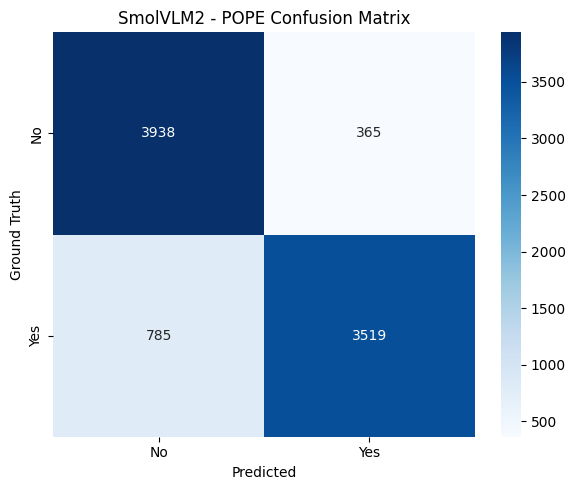

Đã lưu kết quả đánh giá!
{'total_evaluated': 8607, 'accuracy': 0.8663878238642965, 'precision': 0.9060247167868177, 'recall': 0.8176115241635687, 'f1_score': 0.8595505617977528}


In [36]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Đọc kết quả benchmark
df = pd.read_csv(
    "/kaggle/working/pope_smollvm2_checkpoint.csv"
)

# Chỉ lấy các mẫu có kết quả hợp lệ
df = df[
    (df["status"] == "success") &
    (df["ground_truth"].str.lower().isin(["yes", "no"])) &
    (df["prediction"].str.lower().isin(["yes", "no"]))
].copy()

y_true = df["ground_truth"].str.lower()
y_pred = df["prediction"].str.lower()

# Tính các chỉ số đánh giá
metrics = {
    "total_evaluated": len(df),
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(
        y_true, y_pred, pos_label="yes", zero_division=0
    ),
    "recall": recall_score(
        y_true, y_pred, pos_label="yes", zero_division=0
    ),
    "f1_score": f1_score(
        y_true, y_pred, pos_label="yes", zero_division=0
    )
}

# Lưu kết quả JSON
with open(
    "/kaggle/working/evaluation_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics, f, ensure_ascii=False, indent=4)

# Tạo ma trận nhầm lẫn
cm = confusion_matrix(
    y_true, y_pred, labels=["no", "yes"]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Ground Truth")
plt.title("SmolVLM2 - POPE Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/confusion_matrix.png",
    dpi=300
)

plt.show()

print("Đã lưu kết quả đánh giá!")
print(metrics)